# Optimización definitiva de los modelos asimétricos ACrop2 y ACrop3

Fashion-MNIST se ejecuta primero y MNIST después. Para cada dataset se maximiza primero `acc_both` y luego `ssim`. Cada bloque ejecuta los dos estudios, genera sus gráficos de cortes (*slice plots*) y compara los modelos con sus mejores parámetros.

Los estudios usan 100 pruebas, 1.000 mezclas de entrenamiento fijas y 30 iteraciones por prueba. Optuna, la selección del lote de entrenamiento y la evaluación de cada prueba usan la semilla 3333. La comparación usa 10 lotes de prueba de 1.000 mezclas y 50 iteraciones. Cada par de modelos recibe el mismo lote y la misma semilla de evaluación.

Los estudios SQLite, los datos por corrida y los PNG de las comparaciones se guardan en `results_asimetricos/<dataset>/<objetivo>/`, junto a este notebook. Los gráficos de cortes son interactivos y se muestran dentro del notebook. Para regenerar figuras a partir de los archivos, ejecutá las celdas de configuración y funciones, saltá los cuatro bloques de ejecución y usá la sección final.

## Configuración y evaluación

In [2]:
from pathlib import Path
from tempfile import NamedTemporaryFile
import json
import sys

import numpy as np
import optuna

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "project" / "CROP" / "models").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Abrí el notebook desde el repositorio.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "project" / "definitive_experiments" / "results_asimetricos"
SEED = 3333
LAT, INTER = 64, 256
N_IMAGES = 1000
N_TRIALS = 100
STUDY_ITERATIONS = 30
N_RUNS = 10
COMPARISON_ITERATIONS = 50

DATASETS = {"fashion": "Fashion-MNIST", "mnist": "MNIST"}
SEARCH_PARAMS = {"ACrop2": ("gamma",), "ACrop3": ("gamma", "delta")}
SEARCH_BOUNDS = (float(np.nextafter(0.0, 2.0)), float(np.nextafter(2.0, 0.0)))
FIXED_PARAMS = {"alpha_1": -2, "alpha_2": -22, "bias": 0.22, "slope": 22,
                "alpha_mix": 0.5, "beta": 1}
CURVE_KEYS = {"acc_both": "acc_both_plot", "ssim": "ssim_plot", "psnr": "psnr_plot"}


def result_dir(dataset, objective_metric):
    return RESULTS_DIR / dataset / objective_metric


def load_inputs(dataset):
    import tensorflow as tf
    from project.CROP.models.crop2_asimetrico import ACrop2
    from project.CROP.models.crop3_asimetrico import ACrop3
    from project.loader import Loader

    tf.keras.utils.set_random_seed(SEED)
    return (
        Loader.data(dataset),
        Loader.cvae(model_name=f"int_{INTER}_lat_{LAT}_{dataset}.keras"),
        Loader.predictor(dataset=dataset),
        {"ACrop2": ACrop2, "ACrop3": ACrop3},
    )


def sample_batch(data, split, seed):
    rng = np.random.default_rng(seed)
    x0, x1 = data[f"x_{split}"], data[f"x_{split}_1"]
    y0, y1 = data[f"y_{split}"], data[f"y_{split}_1"]
    idx0 = rng.choice(len(x0), size=N_IMAGES, replace=False)
    idx1 = rng.choice(len(x1), size=N_IMAGES, replace=False)
    return (x0[idx0], x1[idx1], y0[idx0], y1[idx1]), (idx0, idx1)


def evaluate(inputs, model_name, batch, tuned_params, seed, iterations, *, curves=False):
    import tensorflow as tf

    data, cvae, predictor, models = inputs
    tf.keras.utils.set_random_seed(seed)
    model = models[model_name](cvae=cvae, predictor=predictor)
    return model.unmix(
        *batch,
        params={**FIXED_PARAMS, **tuned_params},
        iterations=iterations,
        labels=data["labels"],
        show_image=False,
        show_metrics=False,
        save_all_curves=curves,
    )


def scalar_metric(metrics, key):
    value = metrics[key]
    return float(value[0] if isinstance(value, (tuple, list)) else value)

## Estudios y gráficos de cortes

In [3]:
def study_location(dataset, objective_metric, model_name):
    path = result_dir(dataset, objective_metric) / f"{model_name}.sqlite3"
    name = f"{dataset}_{objective_metric}_{model_name}"
    return path, f"sqlite:///{path.as_posix()}", name


def load_study(dataset, objective_metric, model_name):
    path, storage, name = study_location(dataset, objective_metric, model_name)
    if not path.is_file():
        raise FileNotFoundError(f"No se encontró el estudio en {path}")
    return optuna.load_study(storage=storage, study_name=name)


def optimize_model(dataset, objective_metric, model_name, inputs, train_batch):
    path, storage, name = study_location(dataset, objective_metric, model_name)
    path.parent.mkdir(parents=True, exist_ok=True)
    study = optuna.create_study(
        storage=storage,
        study_name=name,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        load_if_exists=True,
    )
    config = {
        "seed": SEED,
        "images": N_IMAGES,
        "iterations": STUDY_ITERATIONS,
        "latent_dim": LAT,
        "intermediate_dim": INTER,
        "fixed_params": FIXED_PARAMS,
        "search_params": list(SEARCH_PARAMS[model_name]),
        "bounds": list(SEARCH_BOUNDS),
    }
    saved_config = study.user_attrs.get("config")
    if saved_config is None and not study.get_trials(deepcopy=False):
        study.set_user_attr("config", config)
    elif saved_config != config:
        raise ValueError(f"La configuración guardada en {path} difiere de la actual.")

    def objective(trial):
        params = {
            key: trial.suggest_float(key, *SEARCH_BOUNDS)
            for key in SEARCH_PARAMS[model_name]
        }
        metrics = evaluate(inputs, model_name, train_batch, params, SEED, STUDY_ITERATIONS)
        score = scalar_metric(metrics, objective_metric)
        if not np.isfinite(score):
            raise ValueError(f"Métrica no finita en {name}: {score}")
        trial.set_user_attr("effective_params", {**FIXED_PARAMS, **params})
        for key in ("acc_both", "ssim", "recon_bpsnr"):
            value = scalar_metric(metrics, key)
            trial.set_user_attr(key, value if np.isfinite(value) else None)
        return score

    completed = study.get_trials(states=(optuna.trial.TrialState.COMPLETE,), deepcopy=False)
    remaining = max(0, N_TRIALS - len(completed))
    if remaining:
        study.optimize(objective, n_trials=remaining, n_jobs=1)

    print(f"{name} · {study.best_value:.6g} · {study.best_params}", flush=True)
    return study


def plot_study(study, dataset, objective_metric, model_name):
    from optuna.visualization import plot_slice

    fig = plot_slice(study, params=list(SEARCH_PARAMS[model_name]),
                     target_name=objective_metric)
    fig.update_layout(title=f"{DATASETS[dataset]} · {model_name} · {objective_metric}")
    fig.show()

## Comparaciones y gráficos

In [4]:
def comparison_config(studies):
    configs = {model: study.user_attrs["config"] for model, study in studies.items()}
    return {
        "seed": SEED,
        "runs": N_RUNS,
        "images": N_IMAGES,
        "iterations": COMPARISON_ITERATIONS,
        "study_configs": configs,
        "best_trials": {model: study.best_trial.number for model, study in studies.items()},
        "best_params": {model: study.best_params for model, study in studies.items()},
    }


def comparison_dir(dataset, objective_metric, config):
    trials = config["best_trials"]
    return result_dir(dataset, objective_metric) / (
        f"comparison_ACrop2_{trials['ACrop2']}_ACrop3_{trials['ACrop3']}"
    )


def read_comparison_run(path, config):
    with np.load(path, allow_pickle=False) as saved:
        if json.loads(saved["config"].item()) != config:
            raise ValueError(f"La configuración guardada en {path} difiere de la actual.")
        return {
            model: {metric: saved[f"{model}_{metric}"] for metric in CURVE_KEYS}
            for model in config["best_params"]
        }


def load_comparison(dataset, objective_metric, studies):
    config = comparison_config(studies)
    folder = comparison_dir(dataset, objective_metric, config)
    runs = [
        read_comparison_run(folder / f"run_{run:02d}.npz", config)
        for run in range(1, config["runs"] + 1)
    ]
    curves = {
        model: {metric: np.stack([run[model][metric] for run in runs])
                for metric in CURVE_KEYS}
        for model in config["best_params"]
    }
    return config, curves


def run_comparison(dataset, objective_metric, studies, inputs):
    config = comparison_config(studies)
    folder = comparison_dir(dataset, objective_metric, config)
    folder.mkdir(parents=True, exist_ok=True)
    seeds = np.random.SeedSequence(config["seed"]).generate_state(config["runs"])
    for run, seed in enumerate(seeds, start=1):
        path = folder / f"run_{run:02d}.npz"
        if path.is_file():
            read_comparison_run(path, config)
            continue

        seed = int(seed)
        print(f"{DATASETS[dataset]} · {objective_metric} · corrida {run}/{config['runs']}",
              flush=True)
        batch, (idx0, idx1) = sample_batch(inputs[0], "test", seed)
        arrays = {
            "config": json.dumps(config),
            "seed": seed,
            "source1_indices": idx0,
            "source2_indices": idx1,
        }
        for model, params in config["best_params"].items():
            metrics = evaluate(inputs, model, batch, params, seed, config["iterations"],
                               curves=True)
            for metric, key in CURVE_KEYS.items():
                arrays[f"{model}_{metric}"] = np.asarray(metrics[key], dtype=float)

        # Publicar la corrida solo después de guardar los resultados de ambos modelos.
        with NamedTemporaryFile(dir=folder, suffix=".tmp", delete=False) as temporary:
            temp_path = Path(temporary.name)
            try:
                np.savez_compressed(temporary, **arrays)
                temporary.close()
                temp_path.replace(path)
            finally:
                temporary.close()
                temp_path.unlink(missing_ok=True)

In [5]:
def plot_comparison(dataset, objective_metric, config, curves):
    import matplotlib.pyplot as plt

    folder = comparison_dir(dataset, objective_metric, config)
    footer = "\n".join(
        f"{model} · " + " | ".join(f"{name} = {value:.10g}" for name, value in params.items())
        for model, params in config["best_params"].items()
    )
    labels = {
        "acc_both": ("Exactitud de ambas fuentes", "Exactitud [%]", 100),
        "ssim": ("SSIM", "SSIM", 1),
        "psnr": ("PSNR", "PSNR [dB]", 1),
    }
    for metric, (title, ylabel, scale) in labels.items():
        fig, ax = plt.subplots(figsize=(9, 6))
        for model, model_curves in curves.items():
            values = model_curves[metric] * scale
            mean, std = values.mean(axis=0), values.std(axis=0)
            iterations = np.arange(1, len(mean) + 1)
            line, = ax.plot(iterations, mean, label=model)
            ax.fill_between(iterations, mean - std, mean + std,
                            color=line.get_color(), alpha=0.2)

        ax.set_title(
            f"{DATASETS[dataset]} · {title} · {config['runs']} corridas\n"
            f"Parámetros optimizados con {objective_metric}"
        )
        ax.set_xlabel("Iteración")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend()
        fig.text(0.5, 0.02, footer, ha="center", va="bottom")
        fig.tight_layout(rect=(0, 0.12, 1, 1))
        fig.savefig(folder / f"{metric}.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)


def run_experiment(dataset, objective_metric):
    inputs = load_inputs(dataset)
    train_batch, _ = sample_batch(inputs[0], "train", SEED)
    studies = {}
    for model in SEARCH_PARAMS:
        study = optimize_model(dataset, objective_metric, model, inputs, train_batch)
        plot_study(study, dataset, objective_metric, model)
        studies[model] = study

    run_comparison(dataset, objective_metric, studies, inputs)
    plot_comparison(dataset, objective_metric,
                    *load_comparison(dataset, objective_metric, studies))

## Fashion-MNIST

I0000 00:00:1795619371.182414     562 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795619371.722956     562 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795619373.349820     562 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Usando fashion como dataset


I0000 00:00:1795619375.919516     562 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9534 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6
[I 2026-11-25 12:09:37,589] A new study created in RDB with name: fashion_acc_both_ACrop2
I0000 00:00:1795619378.181295     562 cuda_dnn.cc:461] Loaded cuDNN version 92801
[I 2026-11-25 12:09:41,436] Trial 0 finished with value: 0.652 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.652.
[I 2026-11-25 12:09:43,058] Trial 1 finished with value: 0.634 and parameters: {'gamma': 0.21850255077708544}. Best is trial 0 with value: 0.652.
[I 2026-11-25 12:09:44,585] Trial 2 finished with value: 0.644 and parameters: {'gamma': 0.9722425581148703}. Best is trial 0 with value: 0.652.
[I 2026-11-25 12:09:46,239] Trial 3 finished with value: 0.643 and parameters: {'gamma': 0.9996623554960683}. Best is trial 0 with value: 0.652.
[I 2026-1

fashion_acc_both_ACrop2 · 0.654 · {'gamma': 1.7362108838752588}


[I 2026-11-25 12:12:07,723] A new study created in RDB with name: fashion_acc_both_ACrop3
[I 2026-11-25 12:12:09,198] Trial 0 finished with value: 0.666 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.666.
[I 2026-11-25 12:12:10,012] Trial 1 finished with value: 0.519 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 0 with value: 0.666.
[I 2026-11-25 12:12:11,394] Trial 2 finished with value: 0.66 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 0 with value: 0.666.
[I 2026-11-25 12:12:12,794] Trial 3 finished with value: 0.667 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 3 with value: 0.667.
[I 2026-11-25 12:12:14,393] Trial 4 finished with value: 0.588 and parameters: {'gamma': 1.424404593266756, 'delta': 0.7451210841006556}. Best is trial 3 with value: 0.667.
[I 2026-11-25 12:12:15,848] Trial 5 fini

fashion_acc_both_ACrop3 · 0.677 · {'gamma': 1.3842297140704185, 'delta': 0.26557193614068647}


Fashion-MNIST · acc_both · corrida 1/10
Fashion-MNIST · acc_both · corrida 2/10
Fashion-MNIST · acc_both · corrida 3/10
Fashion-MNIST · acc_both · corrida 4/10
Fashion-MNIST · acc_both · corrida 5/10
Fashion-MNIST · acc_both · corrida 6/10
Fashion-MNIST · acc_both · corrida 7/10
Fashion-MNIST · acc_both · corrida 8/10
Fashion-MNIST · acc_both · corrida 9/10
Fashion-MNIST · acc_both · corrida 10/10


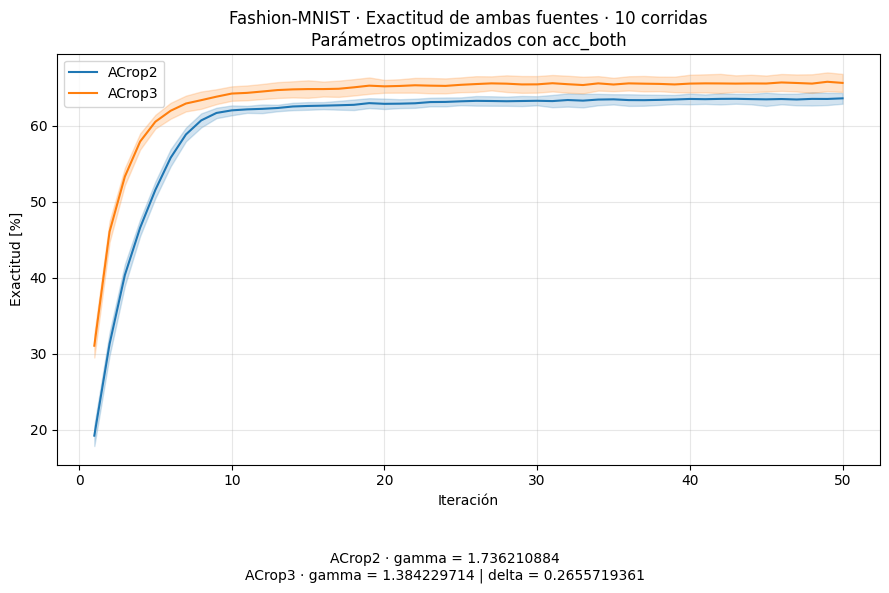

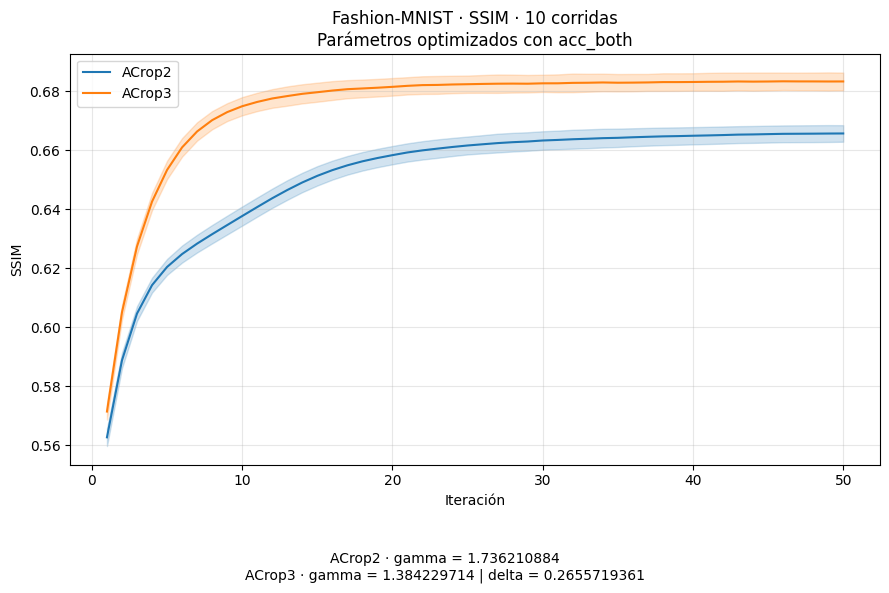

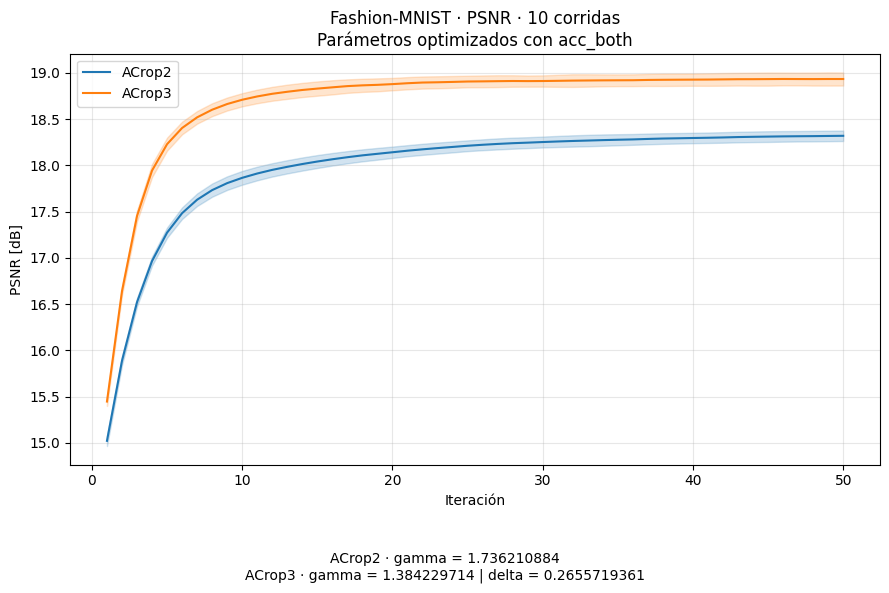

In [6]:
run_experiment("fashion", "acc_both")

Usando fashion como dataset


[I 2026-11-25 12:20:07,388] A new study created in RDB with name: fashion_ssim_ACrop2
[I 2026-11-25 12:20:08,949] Trial 0 finished with value: 0.6661971807479858 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.6661971807479858.
[I 2026-11-25 12:20:10,375] Trial 1 finished with value: 0.6058585047721863 and parameters: {'gamma': 0.21850255077708544}. Best is trial 0 with value: 0.6661971807479858.
[I 2026-11-25 12:20:11,807] Trial 2 finished with value: 0.6520557999610901 and parameters: {'gamma': 0.9722425581148703}. Best is trial 0 with value: 0.6661971807479858.
[I 2026-11-25 12:20:13,437] Trial 3 finished with value: 0.6530514359474182 and parameters: {'gamma': 0.9996623554960683}. Best is trial 0 with value: 0.6661971807479858.
[I 2026-11-25 12:20:15,023] Trial 4 finished with value: 0.6623295545578003 and parameters: {'gamma': 1.3142199980396863}. Best is trial 0 with value: 0.6661971807479858.
[I 2026-11-25 12:20:16,573] Trial 5 finished with value: 0

fashion_ssim_ACrop2 · 0.666632 · {'gamma': 1.5997906840753306}


[I 2026-11-25 12:22:33,994] A new study created in RDB with name: fashion_ssim_ACrop3
[I 2026-11-25 12:22:35,528] Trial 0 finished with value: 0.6835095882415771 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.6835095882415771.
[I 2026-11-25 12:22:36,941] Trial 1 finished with value: 0.6225842237472534 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 0 with value: 0.6835095882415771.
[I 2026-11-25 12:22:38,517] Trial 2 finished with value: 0.6878567934036255 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 2 with value: 0.6878567934036255.
[I 2026-11-25 12:22:40,028] Trial 3 finished with value: 0.6808164119720459 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 2 with value: 0.6878567934036255.
[I 2026-11-25 12:22:41,460] Trial 4 finished with value: 0.6760287880897522 and parameters: {'gamma': 1.42440459

fashion_ssim_ACrop3 · 0.69058 · {'gamma': 1.5804613261209475, 'delta': 0.4578152991374176}


Fashion-MNIST · ssim · corrida 1/10
Fashion-MNIST · ssim · corrida 2/10
Fashion-MNIST · ssim · corrida 3/10
Fashion-MNIST · ssim · corrida 4/10
Fashion-MNIST · ssim · corrida 5/10
Fashion-MNIST · ssim · corrida 6/10
Fashion-MNIST · ssim · corrida 7/10
Fashion-MNIST · ssim · corrida 8/10
Fashion-MNIST · ssim · corrida 9/10
Fashion-MNIST · ssim · corrida 10/10


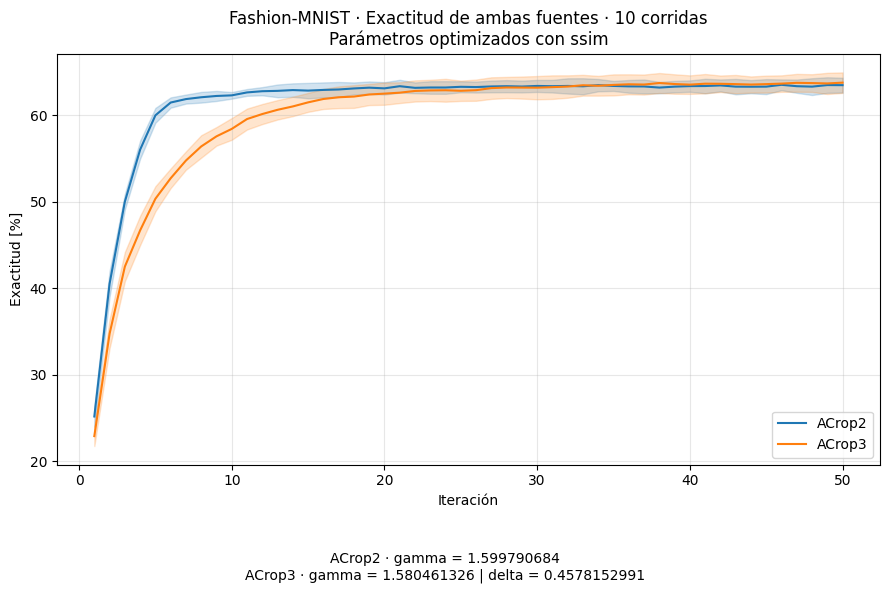

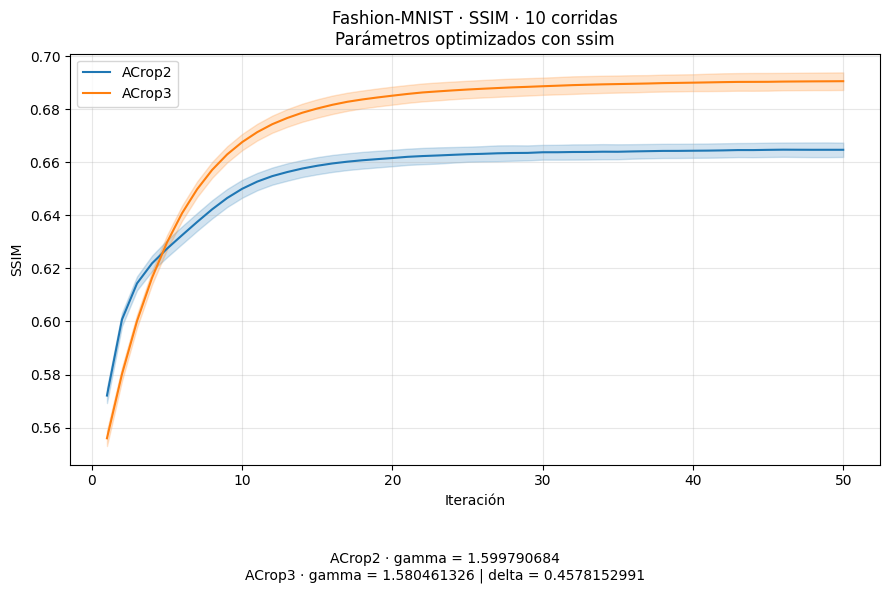

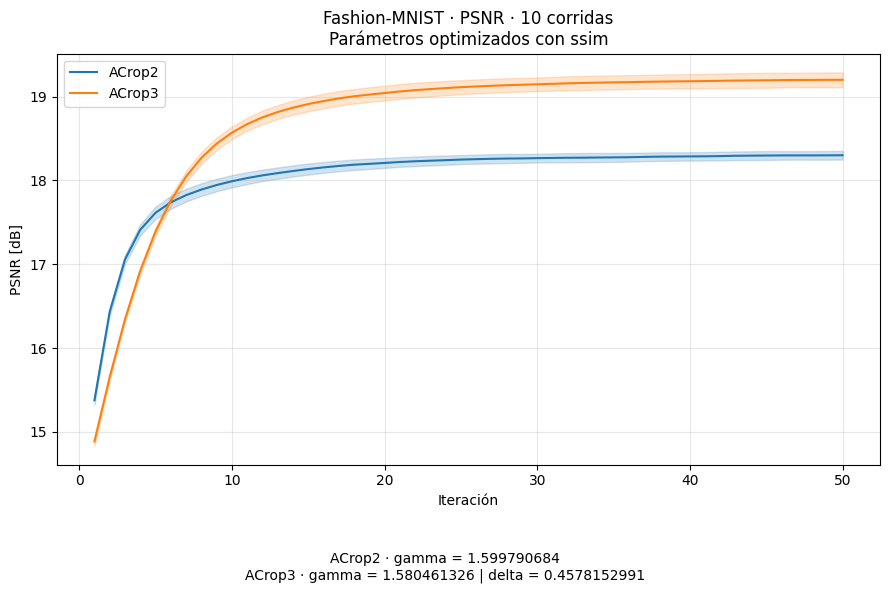

In [7]:
run_experiment("fashion", "ssim")

## MNIST

Usando mnist como dataset


[I 2026-11-25 12:30:34,152] A new study created in RDB with name: mnist_acc_both_ACrop2
[I 2026-11-25 12:30:35,719] Trial 0 finished with value: 0.841 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.841.
[I 2026-11-25 12:30:37,123] Trial 1 finished with value: 0.866 and parameters: {'gamma': 0.21850255077708544}. Best is trial 1 with value: 0.866.
[I 2026-11-25 12:30:38,593] Trial 2 finished with value: 0.851 and parameters: {'gamma': 0.9722425581148703}. Best is trial 1 with value: 0.866.
[I 2026-11-25 12:30:40,007] Trial 3 finished with value: 0.852 and parameters: {'gamma': 0.9996623554960683}. Best is trial 1 with value: 0.866.
[I 2026-11-25 12:30:41,399] Trial 4 finished with value: 0.846 and parameters: {'gamma': 1.3142199980396863}. Best is trial 1 with value: 0.866.
[I 2026-11-25 12:30:42,893] Trial 5 finished with value: 0.863 and parameters: {'gamma': 0.47176942248161374}. Best is trial 1 with value: 0.866.
[I 2026-11-25 12:30:44,369] Trial 6 fini

mnist_acc_both_ACrop2 · 0.868 · {'gamma': 0.23930480679487684}


[I 2026-11-25 12:32:59,077] A new study created in RDB with name: mnist_acc_both_ACrop3
[I 2026-11-25 12:33:00,524] Trial 0 finished with value: 0.854 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.854.
[I 2026-11-25 12:33:01,923] Trial 1 finished with value: 0.762 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 0 with value: 0.854.
[I 2026-11-25 12:33:03,369] Trial 2 finished with value: 0.851 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 0 with value: 0.854.
[I 2026-11-25 12:33:04,932] Trial 3 finished with value: 0.861 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 3 with value: 0.861.
[I 2026-11-25 12:33:05,444] Trial 4 finished with value: 0.812 and parameters: {'gamma': 1.424404593266756, 'delta': 0.7451210841006556}. Best is trial 3 with value: 0.861.
[I 2026-11-25 12:33:06,860] Trial 5 finis

mnist_acc_both_ACrop3 · 0.882 · {'gamma': 0.11007977221714971, 'delta': 0.1631189714000348}


MNIST · acc_both · corrida 1/10
MNIST · acc_both · corrida 2/10
MNIST · acc_both · corrida 3/10
MNIST · acc_both · corrida 4/10
MNIST · acc_both · corrida 5/10
MNIST · acc_both · corrida 6/10
MNIST · acc_both · corrida 7/10
MNIST · acc_both · corrida 8/10
MNIST · acc_both · corrida 9/10
MNIST · acc_both · corrida 10/10


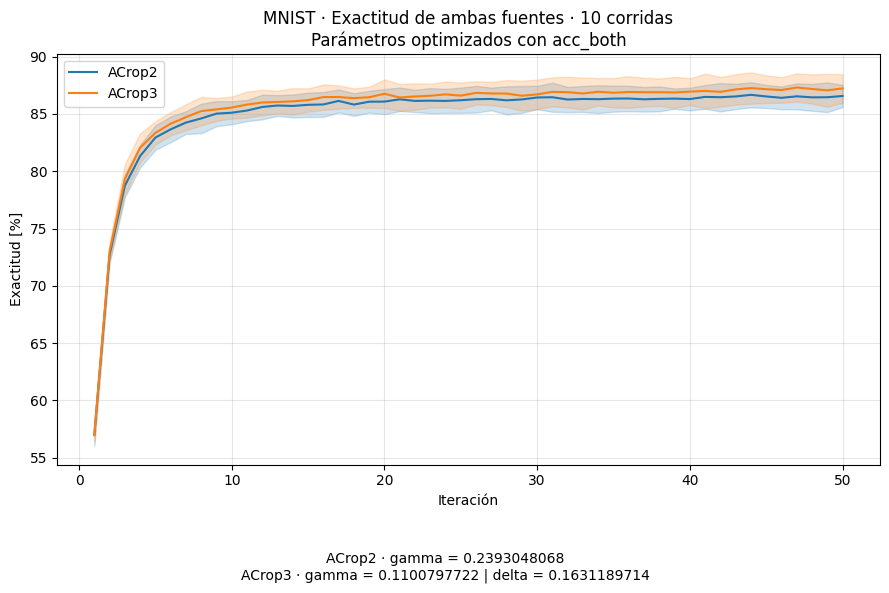

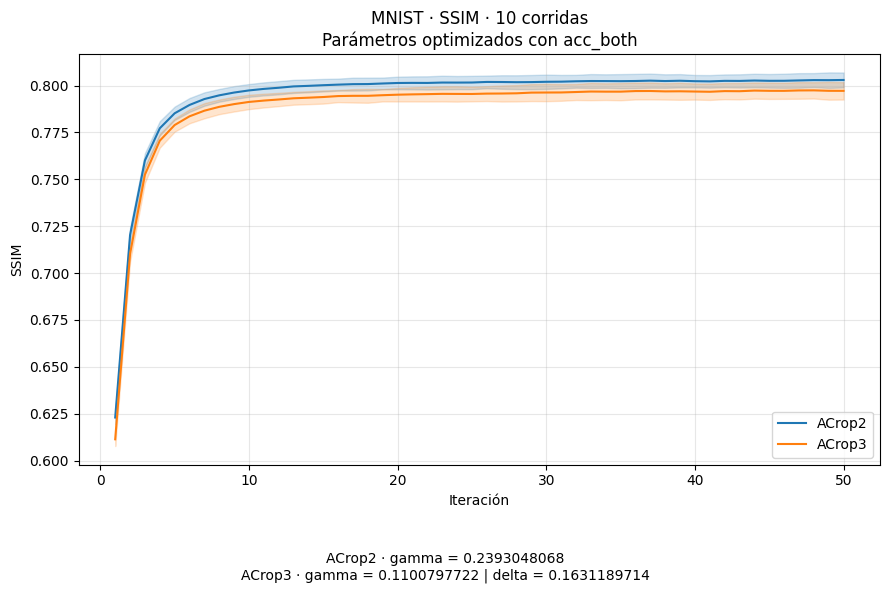

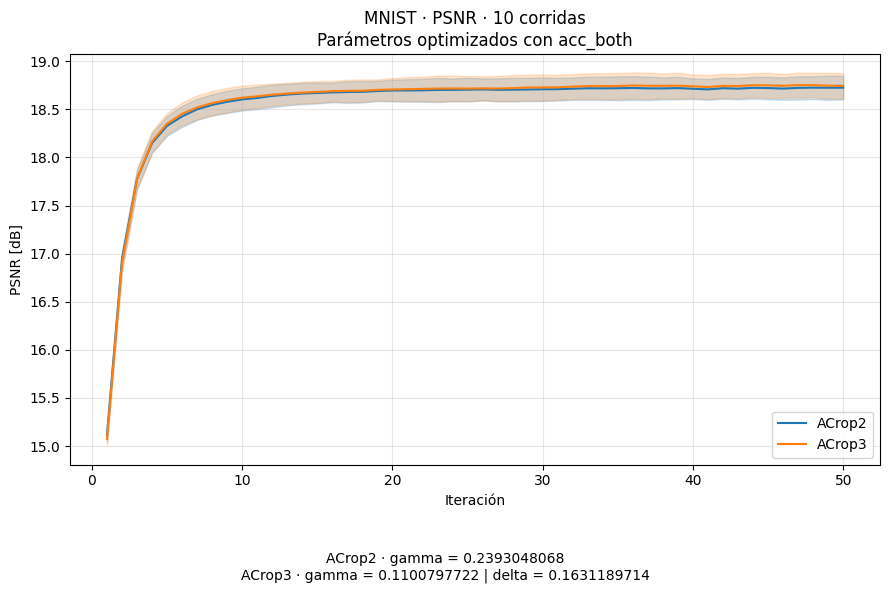

In [8]:
run_experiment("mnist", "acc_both")

Usando mnist como dataset


[I 2026-11-25 12:40:57,694] A new study created in RDB with name: mnist_ssim_ACrop2
[I 2026-11-25 12:40:59,300] Trial 0 finished with value: 0.8146885633468628 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.8146885633468628.
[I 2026-11-25 12:41:00,885] Trial 1 finished with value: 0.802652895450592 and parameters: {'gamma': 0.21850255077708544}. Best is trial 0 with value: 0.8146885633468628.
[I 2026-11-25 12:41:02,455] Trial 2 finished with value: 0.8145054578781128 and parameters: {'gamma': 0.9722425581148703}. Best is trial 0 with value: 0.8146885633468628.
[I 2026-11-25 12:41:04,034] Trial 3 finished with value: 0.8150060176849365 and parameters: {'gamma': 0.9996623554960683}. Best is trial 3 with value: 0.8150060176849365.
[I 2026-11-25 12:41:05,542] Trial 4 finished with value: 0.8158461451530457 and parameters: {'gamma': 1.3142199980396863}. Best is trial 4 with value: 0.8158461451530457.
[I 2026-11-25 12:41:07,077] Trial 5 finished with value: 0.80

mnist_ssim_ACrop2 · 0.816377 · {'gamma': 1.29750189832331}


[I 2026-11-25 12:43:29,091] A new study created in RDB with name: mnist_ssim_ACrop3
[I 2026-11-25 12:43:30,635] Trial 0 finished with value: 0.8069013357162476 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.8069013357162476.
[I 2026-11-25 12:43:32,280] Trial 1 finished with value: 0.7055503129959106 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 0 with value: 0.8069013357162476.
[I 2026-11-25 12:43:33,792] Trial 2 finished with value: 0.7887825965881348 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 0 with value: 0.8069013357162476.
[I 2026-11-25 12:43:35,285] Trial 3 finished with value: 0.8076013326644897 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 3 with value: 0.8076013326644897.
[I 2026-11-25 12:43:36,770] Trial 4 finished with value: 0.7596763372421265 and parameters: {'gamma': 1.4244045932

mnist_ssim_ACrop3 · 0.816294 · {'gamma': 1.0930674433875862, 'delta': 0.0002624951091941283}


MNIST · ssim · corrida 1/10
MNIST · ssim · corrida 2/10
MNIST · ssim · corrida 3/10
MNIST · ssim · corrida 4/10
MNIST · ssim · corrida 5/10
MNIST · ssim · corrida 6/10
MNIST · ssim · corrida 7/10
MNIST · ssim · corrida 8/10
MNIST · ssim · corrida 9/10
MNIST · ssim · corrida 10/10


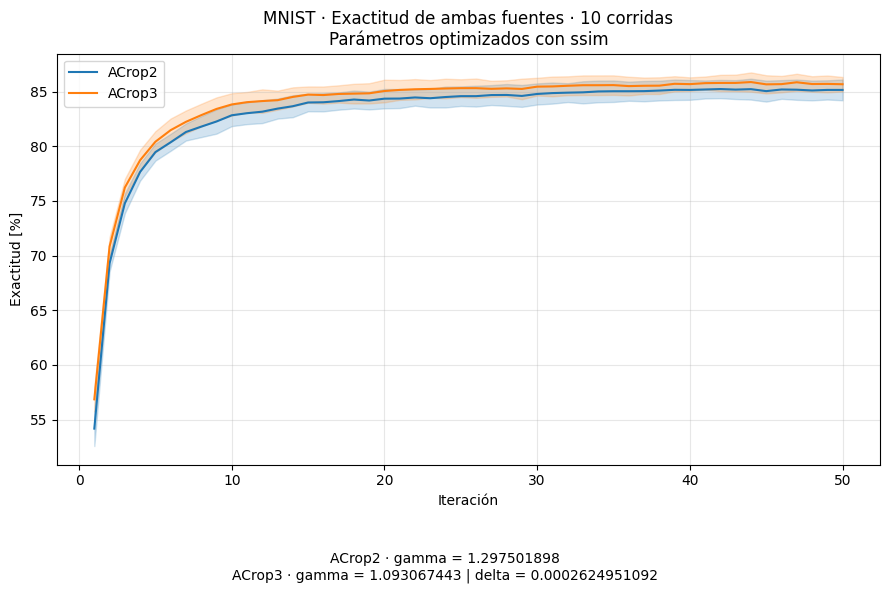

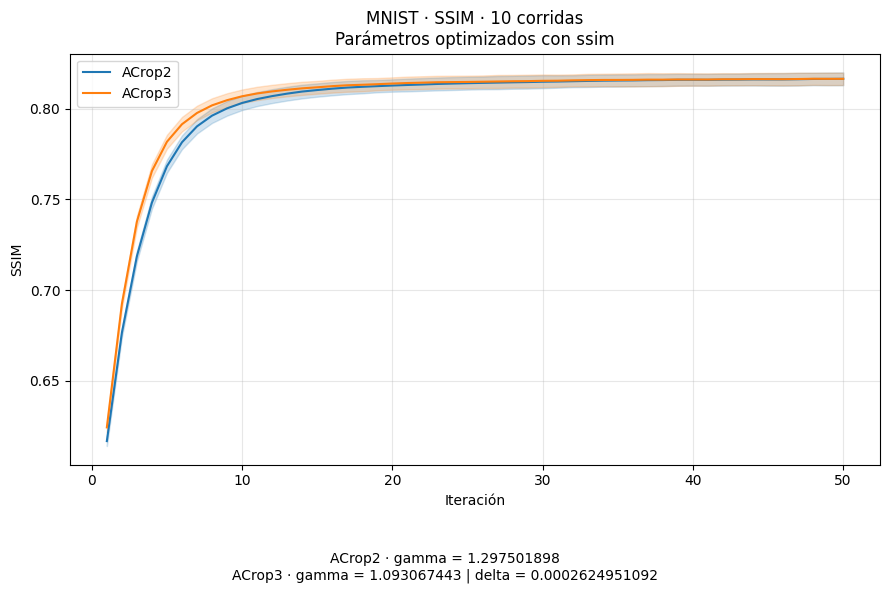

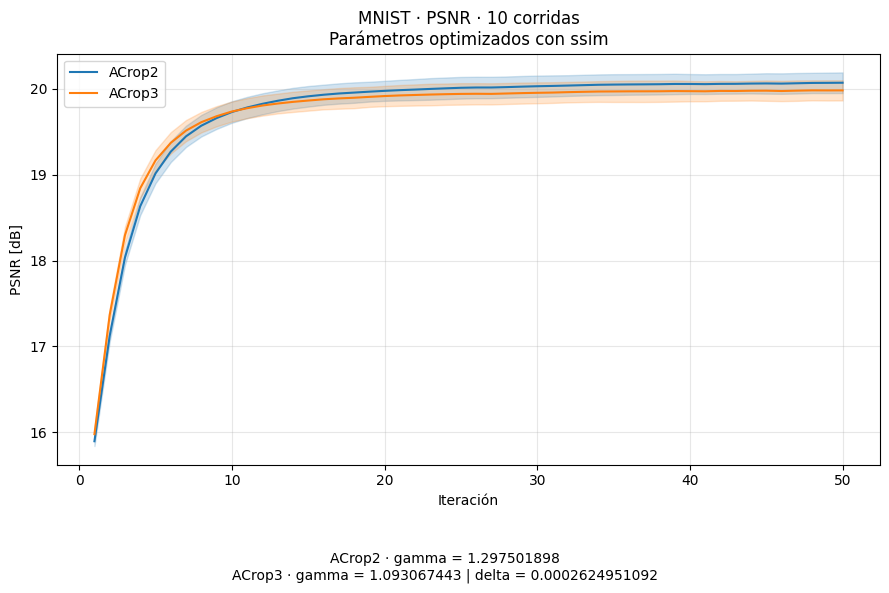

In [9]:
run_experiment("mnist", "ssim")

## Recuperar resultados guardados

Elegí el dataset y la métrica objetivo. Estas celdas cargan los estudios y las curvas por corrida desde disco, muestran los gráficos interactivos de Optuna y vuelven a guardar los PNG de las comparaciones. Las bandas de la comparación representan media ± un desvío estándar entre las 10 corridas.

In [10]:
dataset, objective_metric = "fashion", "acc_both"

saved_studies = {
    model: load_study(dataset, objective_metric, model)
    for model in SEARCH_PARAMS
}
for model, study in saved_studies.items():
    print(f"{model} · {study.best_value:.6g} · {study.best_params}")
    plot_study(study, dataset, objective_metric, model)

ACrop2 · 0.654 · {'gamma': 1.7362108838752588}


ACrop3 · 0.677 · {'gamma': 1.3842297140704185, 'delta': 0.26557193614068647}


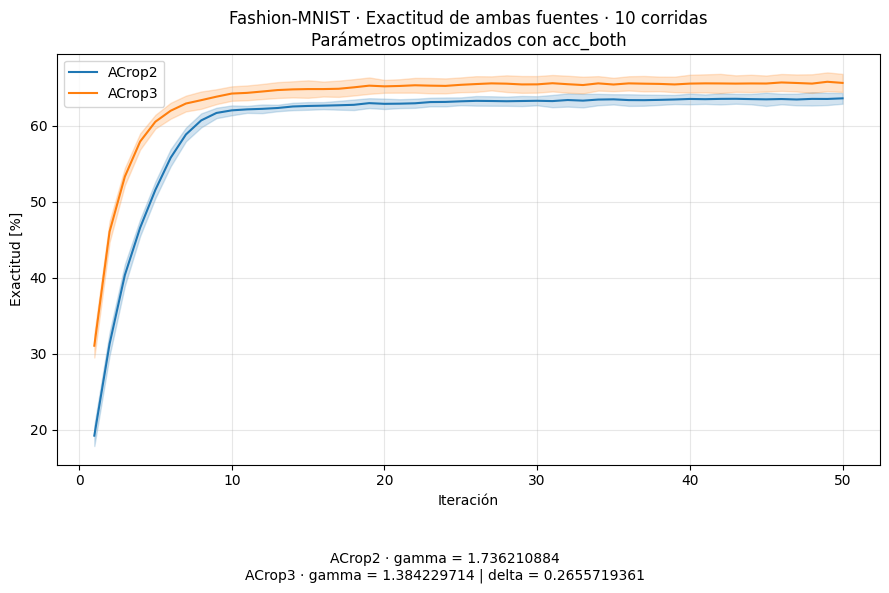

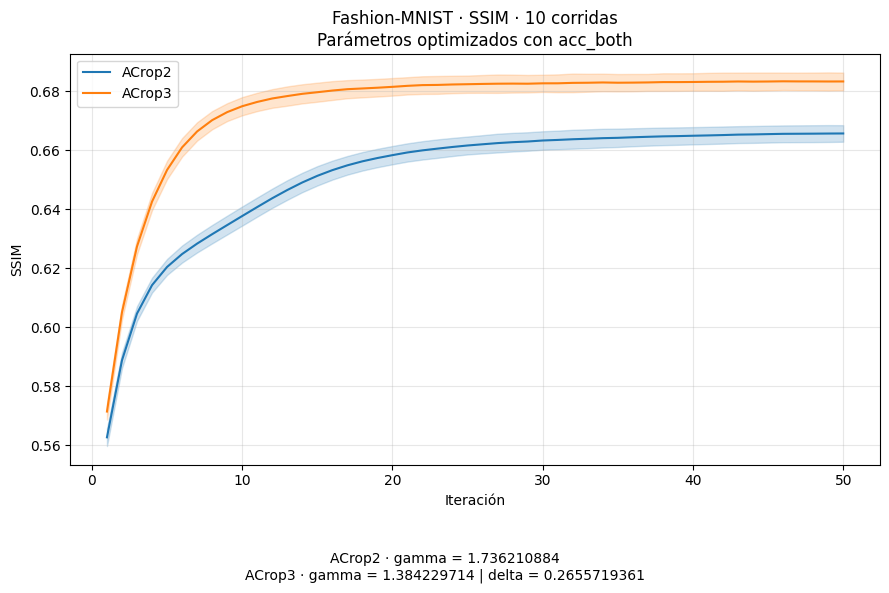

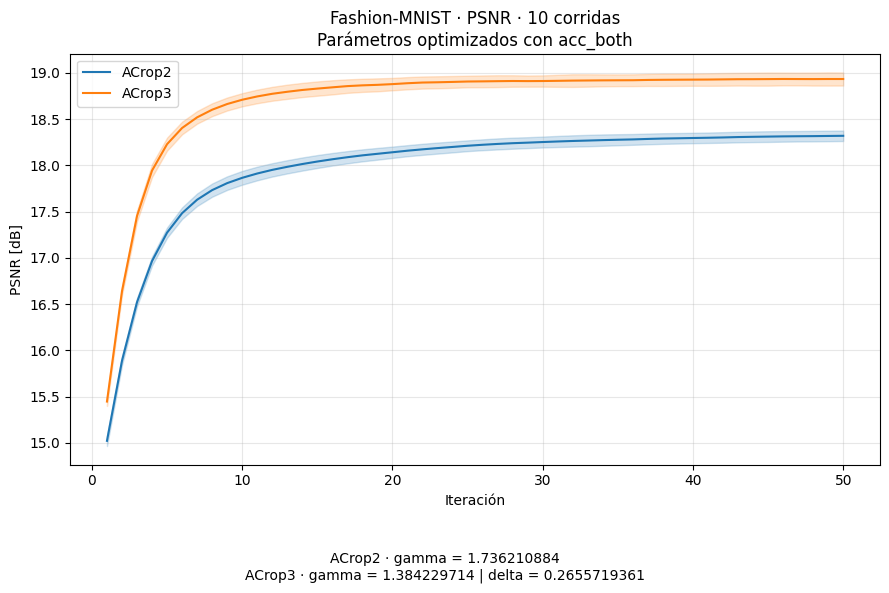

In [11]:
saved_config, saved_curves = load_comparison(dataset, objective_metric, saved_studies)
plot_comparison(dataset, objective_metric, saved_config, saved_curves)